In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.ticker import FuncFormatter
import matplotlib
from eda_manager.chart.chart_helper import common_option
from fonts import get_project_font
from eda_manager.chart.chart_helper import (init_figure_axes,
                                            update_chart_with_common_option,
                                            save_chart_to_bytes, save_gif_chart_to_bytes,
                                            formatter_kmb,
                                            close_pyplot)

FONT_GOTHIC_PATH, FONT_DREAM_PATH = get_project_font()

matplotlib.use("agg")
DBGOTHIC = fm.FontProperties(fname=FONT_GOTHIC_PATH)
DBDREAM = fm.FontProperties(fname=FONT_DREAM_PATH)
fm.fontManager.addfont(FONT_GOTHIC_PATH)
fm.fontManager.addfont(FONT_DREAM_PATH)

plt.rcParams['font.family'] = DBGOTHIC.get_name()
plt.rcParams['axes.unicode_minus'] = False

def display_img_bytes(img_bytes):
    import base64
    from IPython.display import Image, display

    image_data = base64.b64decode(img_bytes)
    display(Image(data=image_data))

In [2]:
from eda_manager.chart.custom.chart_group import proportion
from eda_manager.chart.chart_helper import common_option
def display_img_bytes(img_bytes):
    import base64
    from IPython.display import Image, display

    image_data = base64.b64decode(img_bytes)
    display(Image(data=image_data))

In [3]:
# project_dir = r"C:\Users\10007166\insightmaker_project\Boston 데이터셋 분석"
project_dir = r"C:\Users\10007166\insightmaker_project\WORDCLOUD"

In [4]:
# 1. 파이차트 : 범주, 이산형(20개 이하)
"""
1. 카테고리 수 > 7 → 병합
2. 개별 비중 < 1% → 기타
3. 누적 95%까지만 표시
4. 내림차순 정렬
5. 기타는 회색
"""

'\n1. 카테고리 수 > 7 → 병합\n2. 개별 비중 < 1% → 기타\n3. 누적 95%까지만 표시\n4. 내림차순 정렬\n5. 기타는 회색\n'

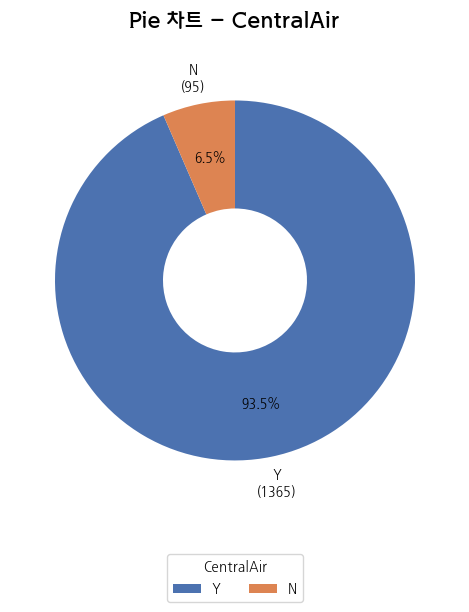

In [8]:
# cat = "MSZoning" # Categorical, 5개
cat = "CentralAir"
# cat = "MSSubClass" # Discrete, 15개
# cat = "LotShape" # Categorical, 4개
# cat = "Neighborhood" # Categorical, 25개
# cat = "Condition1" # Categorical, 9개

options_1 = {
    "project_dir": project_dir,
    "cat": cat,
    "use_etc": True,
    "show_etc_detail": True,
    "common_option": common_option(
        chart_nm="auto", chart_nm_font_size="auto",
        axis_font_size="auto",        
        x_size=12, y_size=6
    )
}

chart_func = proportion.pie_chart
img_bytes = chart_func(**options_1)
display_img_bytes(img_bytes)

Bitmap missing for glyph


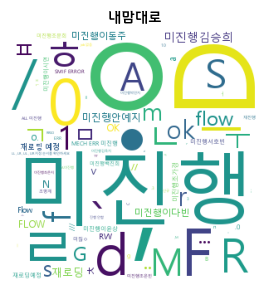

In [4]:
# 2. 워드클라우드 : 범주, 이산형(20개 이하)
# cat = "MSZoning" # Categorical, 5개
# cat = "MSSubClass" # Discrete, 15개
# cat = "LotShape" # Categorical, 4개
# cat = "Neighborhood" # Categorical, 25개
# cat = "Condition1" # Categorical, 9개
cat = "MAINT_REMARK"

options_2 = {
    "project_dir": project_dir,
    "cat": cat,
    "common_option": common_option(
        chart_nm="내맘대로", chart_nm_font_size="11",
        x_size=3, y_size=3
    )
}

chart_func = proportion.wordcloud_chart
img_bytes = chart_func(**options_2)
display_img_bytes(img_bytes)

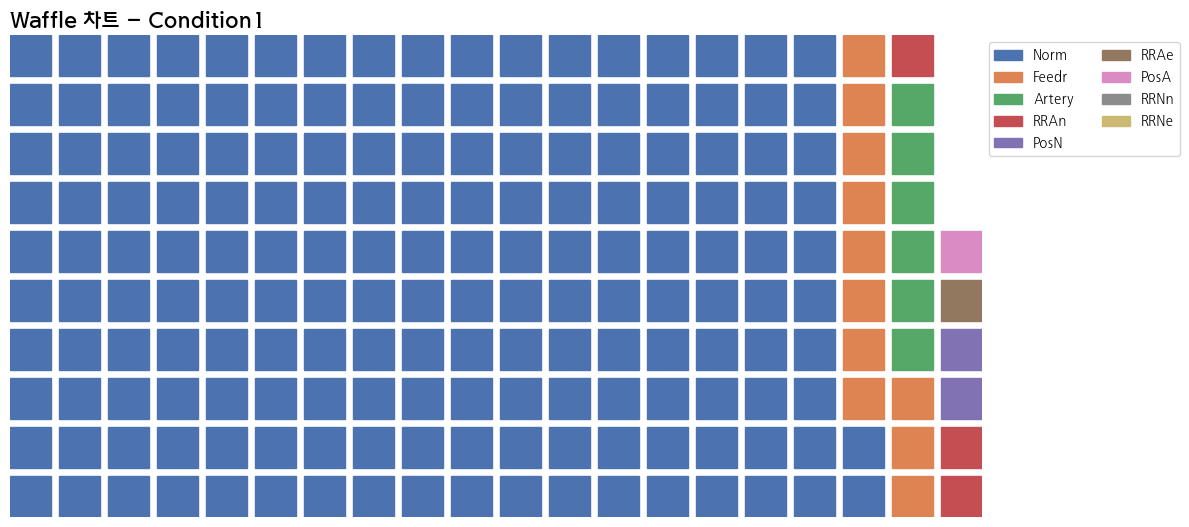

In [7]:
# 3. 와플차트 : 범주, 이산형(20개 이하)
# cat = "MSZoning" # Categorical, 5개
# cat = "MSSubClass" # Discrete, 15개
# cat = "LotShape" # Categorical, 4개
# cat = "Neighborhood" # Categorical, 25개
cat = "Condition1" # Categorical, 9개

options_3 = {
    "project_dir": project_dir,
    "cat": cat,
    "nrow": 10, "ncol": 20,
    "scale_type": "floor",
    "common_option": common_option(
        chart_nm="auto", chart_nm_font_size="15",
        x_size=12, y_size=6
    )
}

chart_func = proportion.waffle_chart
img_bytes = chart_func(**options_3)
display_img_bytes(img_bytes)

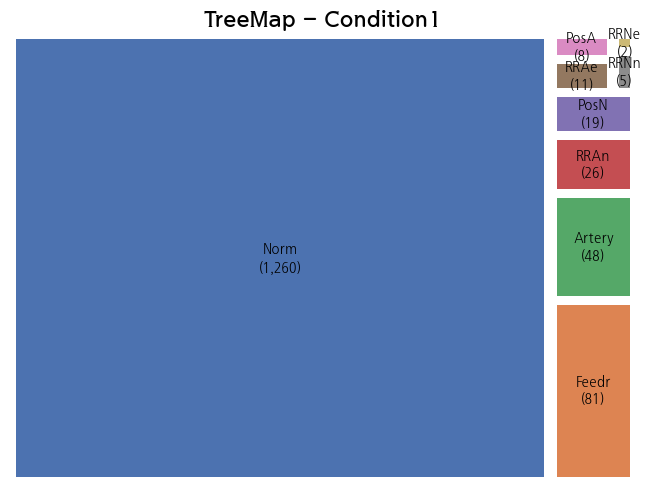

In [8]:
# 4. 트리맵 : 범주, 이산형(20개 이하)
cat = "MSZoning" # Categorical, 5개
# cat = "MSSubClass" # Discrete, 15개
# cat = "LotShape" # Categorical, 4개
# cat = "Neighborhood" # Categorical, 25개
cat = "Condition1" # Categorical, 9개

options_4 = {
    "project_dir": project_dir,
    "cat": cat,
    "common_option": common_option(
        chart_nm="auto", chart_nm_font_size="15",
        x_size="auto", y_size="auto"
    )
}

chart_func = proportion.treemap_chart
img_bytes = chart_func(**options_4)
display_img_bytes(img_bytes)

In [9]:
# cat = "MSZoning" # Categorical, 5개
# cat = "MSSubClass" # Discrete, 15개
# cat = "LotShape" # Categorical, 4개
# cat = "Neighborhood" # Categorical, 25개
cat = "Condition1" # Categorical, 9개

df = pd.read_pickle(os.path.join(project_dir, "data.pkl"))

In [10]:
df_prop, df_detail = proportion.split_prop_others(df, cat)

In [11]:
df_prop

,Condition1,count,cumsum,ratio,cumratio
0,Norm,1260,1260,0.863014,0.863014
1,Feedr,81,1341,0.055479,0.918493
2,Artery,48,1389,0.032877,0.951370
3,기타,71,1460,0.048630,1.000000


In [12]:
df_detail

,Condition1,count,ratio
0,RRAn,26,0.017808
1,PosN,19,0.013014
2,RRAe,11,0.007534
3,PosA,8,0.005479
4,RRNn,5,0.003425
5,RRNe,2,0.001370


In [13]:
import matplotlib.ticker as mtick

In [36]:
cat = "MSZoning"
use_etc = "auto"
show_etc_detail = "auto"
common_ops = common_option(
    chart_nm="auto",
    chart_nm_font_size="auto",
    x_size=10, y_size=5
)

In [46]:
data_path = os.path.join(project_dir, "data.pkl")
df = pd.read_pickle(data_path)
# series = df[cat].astype(str)
df_prop, df_others = proportion.split_prop_others(df, cat, use_etc)

In [47]:
df_prop

,MSZoning,count,cumsum,ratio,cumratio
0,RL,1151,1151,0.788356,0.788356
1,RM,218,1369,0.149315,0.937671
2,FV,65,1434,0.044521,0.982192
3,기타,26,1460,0.017808,1.000000


In [50]:
%matplotlib inline

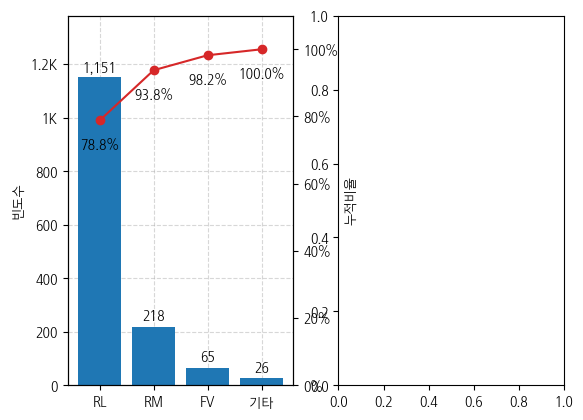

In [82]:
fig, ax = plt.subplots(ncols=2)

paretos = ax[0].bar(df_prop[cat], df_prop["count"])
ax[0].bar_label(paretos, label_type="edge", fmt=lambda x : f'{x:,.0f}', padding=2)
ax[0].set_ylim(top=df_prop["count"].max()*1.2)
ax[0].yaxis.set_major_formatter(FuncFormatter(formatter_kmb))
ax[0].grid(True, linestyle='--', alpha=.5)
ax[0].set_axisbelow(True)
ax[0].set_ylabel("빈도수")

cumratio = ax[0].twinx()
cumratio.plot(df_prop[cat], df_prop["cumratio"], color="tab:red", marker="o")
for i, ratio in enumerate(df_prop["cumratio"].values):
    cumratio.text(df_prop[cat].values[i], ratio, f"\n{ratio:.1%}", ha="center", va="top")
cumratio.set_ylim(bottom=0.0, top=1.1)
cumratio.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
cumratio.set_ylabel("누적비율")

plt.show()

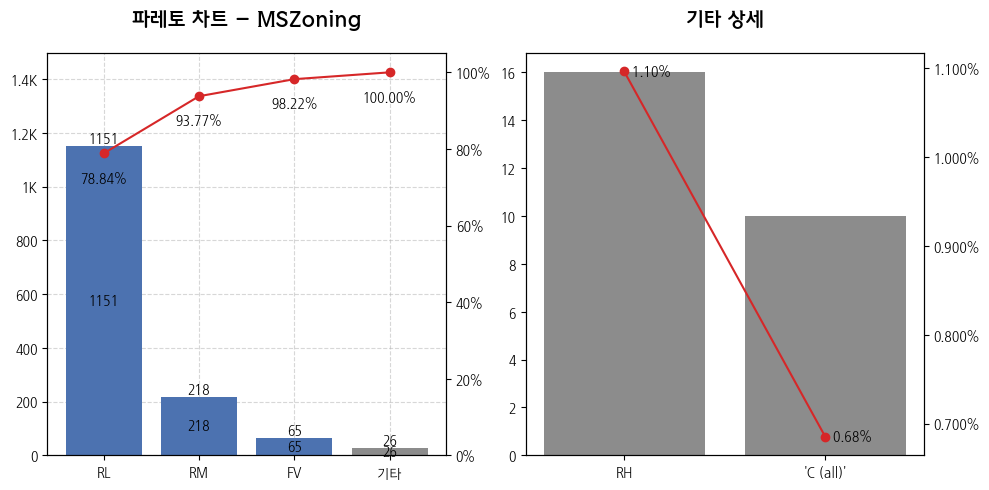

In [45]:
img = None
data_path = os.path.join(project_dir, 'data.pkl')
# try:
df = pd.read_pickle(data_path)
df[cat] = df[cat].astype(str)
auto_title = f"파레토 차트 - {cat}"
use_etc = True if use_etc=="auto" else use_etc
df_prop, df_others = proportion.split_prop_others(df, cat, use_etc)
colors = ["#4c72b0" for _ in range(len(df_prop))]
gray_color = "#8c8c8c"
colors = colors[:len(df_prop)]
if "기타" in df_prop[cat].values:
    colors[-1] = gray_color

size_x, size_y = common_ops['x_size'], common_ops['y_size']
chart_nm = common_ops.get("chart_nm", None)
chart_nm_font_size = common_ops.get("chart_nm_font_size", 15)
chart_nm_font_size = 15 if chart_nm_font_size=="auto" else chart_nm_font_size

fig, ax = None, None
if use_etc and show_etc_detail and df_others is not None:
    df_others[cat] = df_others[cat].astype(str)
    fig, ax = init_figure_axes(size_x, size_y, ncols=2)
    paretos = ax[0].bar(df_prop[cat], df_prop["count"], color=colors)
    ax[0].bar_label(paretos, label_type="edge")
    # ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=-45, ha='center')
    ax[0].set_ylim(top=df_prop["count"].max()*1.3)
    ax[0].yaxis.set_major_formatter(FuncFormatter(formatter_kmb))
    cumratio = ax[0].twinx()
    cumratio.set_ylim(0,1.05)
    cumratio.plot(df_prop[cat], df_prop["cumratio"], marker="o", color="tab:red")
    for i, ratio in enumerate(df_prop["cumratio"].values):
        cumratio.text(df_prop[cat].values[i], ratio,
                    # f"{ratio:.2%}\n", ha="center", va="bottom")
                    f"\n{ratio:.2%}", ha="center", va="top")
    cumratio.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax[0].grid(True, linestyle='--', alpha=.5)
    chart_nm = auto_title if chart_nm=="auto" else chart_nm
    ax[0].set_title(chart_nm, fontdict=dict(fontsize=chart_nm_font_size,
        fontweight='bold', fontproperties=DBDREAM), y=1.05, pad=5)
    ax[0].set_axisbelow(True)
    
    ax[1].bar(df_others[cat], df_others["count"], color=gray_color)
    ax[1].bar_label(paretos, label_type="center")
    ratio_etc = ax[1].twinx()
    ratio_etc.plot(df_others[cat], df_others["ratio"], marker="o", color="tab:red")
    for i, ratio in enumerate(df_others["ratio"].values):
        ratio_etc.text(df_others[cat].values[i], ratio,
                    f"  {ratio:.2%}", ha="left", va="center")
    ratio_etc.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax[1].set_axisbelow(True)
    ax[1].set_title("기타 상세", fontdict=dict(fontsize=chart_nm_font_size,
        fontweight='bold', fontproperties=DBDREAM), y=1.05, pad=5)
else:
    if not show_etc_detail:
        if "기타" in df_prop[cat].values:
            colors[-1] = gray_color
    fig, ax = init_figure_axes(size_x, size_y)
    paretos = ax[0].bar(df_prop[cat], df_prop["count"], color=colors)
    ax[0].bar_label(paretos, label_type="center", padding=3)
    ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=-45, ha='center')
    cumratio = ax[0].twinx()
    cumratio.plot(df_prop[cat], df_prop["cumratio"], marker="o", color="tab:red")
    for i, ratio in enumerate(df_others["cumratio"].values):
        cumratio.text(df_prop[cat].values[i], ratio,
                    f"  {ratio:.2%}", ha="left", va="center")
    ax[0].grid(True, linestyle='--', alpha=.5)
    chart_nm = auto_title if chart_nm=="auto" else chart_nm
    ax[0].set_title(chart_nm, fontdict=dict(fontsize=chart_nm_font_size,
        fontweight='bold', fontproperties=DBDREAM), y=1.05, pad=5)
fig.tight_layout()
plt.subplots_adjust(wspace=0.2, hspace=0)
img = save_chart_to_bytes(fig)
# except Exception as e:
#     print(e)
close_pyplot()

display_img_bytes(img)